# Trend Scanning

Introducing to trend scanning method

# Trend Scanning

Introducing to trend scanning method

In [426]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"

In [427]:
df = pd.read_parquet(DATASETS_DIR / "6a915d3a25d574ce/volume.parquet")

In [428]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(df)

In [429]:
df = df[~df.index.duplicated(keep="first")]

## CUSUM Filter

For now, we are applying Trend Scanning to the volume-bar dataset using events selected by the CUSUM filter.

There are two distinct approaches worth investigating:

1. **CUSUM-based Trend Scanning:** Treat each CUSUM event as an individual observation and perform Trend Scanning over consecutive CUSUM events.
2. **Volume-bar Trend Scanning:** Use each CUSUM event as a starting point and perform Trend Scanning over the subsequent volume bars.

The first approach captures longer-term trends, while the second focuses on shorter-term, local trends, assuming the same look-forward window.

I will start by testing the first approach and then compare the results to understand how the choice of sampling affects trend identification and labeling.

In [430]:
from mlfinpy.filters import cusum_filter

cusum_events = cusum_filter(
    raw_time_series=df['close'],
    threshold=0.05
)

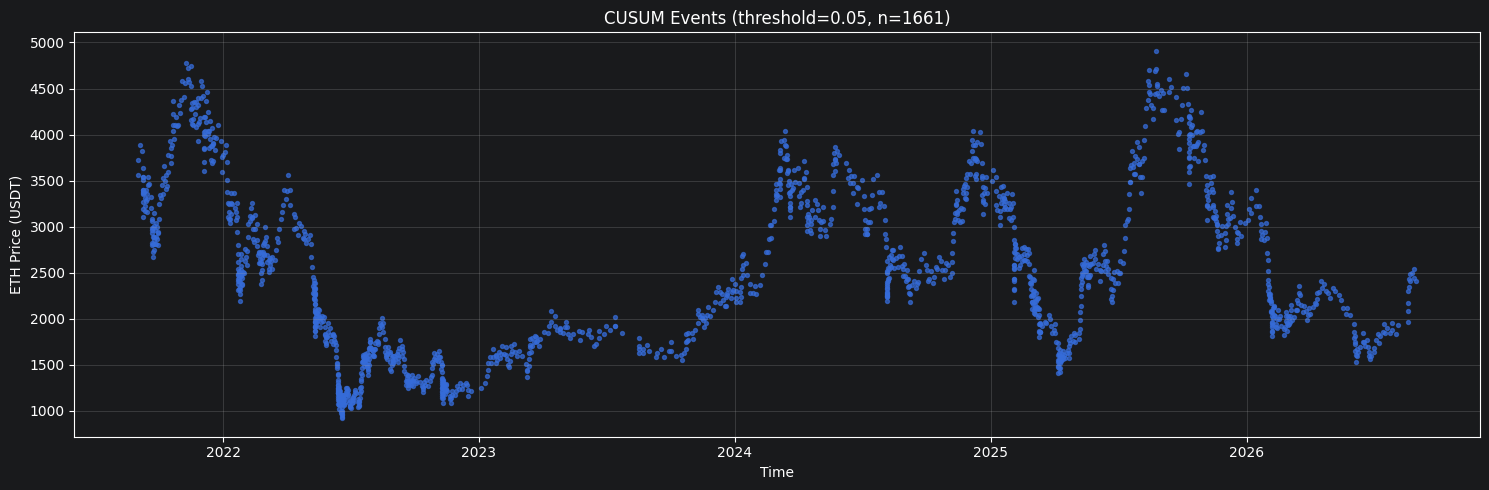

In [431]:
import matplotlib.pyplot as plt

events = df.loc[cusum_events, "close"]

plt.figure(figsize=(15, 5))
plt.scatter(events.index, events.values, s=8, alpha=0.7)
plt.title(f"CUSUM Events (threshold=0.05, n={len(events)})")
plt.xlabel("Time")
plt.ylabel("ETH Price (USDT)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [432]:
from mlfinpy.labeling import trend_scanning_labels

cusum_prices = df.loc[cusum_events, "close"].astype(float).sort_index()

tr_scan_labels = trend_scanning_labels(
    price_series=cusum_prices,
    t_events=cusum_prices.index,
    look_forward_window=20,
    min_sample_length=10
)

print(f"Evenimente CUSUM: {len(cusum_prices)}")
display(tr_scan_labels.head())

Evenimente CUSUM: 1661


,t1,t_value,ret,bin
2021-09-01 14:31:21.082000+00:00,2021-09-07 15:17:57.227000+00:00,-3.353013,-0.053646,-1.0
2021-09-01 16:46:13.443000+00:00,2021-09-11 10:24:55.369000+00:00,-2.860464,-0.109393,-1.0
2021-09-03 08:50:28.625000+00:00,2021-09-11 10:24:55.369000+00:00,-2.365062,-0.145972,-1.0
2021-09-07 08:27:37.376000+00:00,2021-09-13 02:31:17.144000+00:00,-1.631185,-0.142295,-1.0
2021-09-07 14:43:58.672000+00:00,2021-09-13 02:31:17.144000+00:00,-0.724518,-0.099910,-1.0


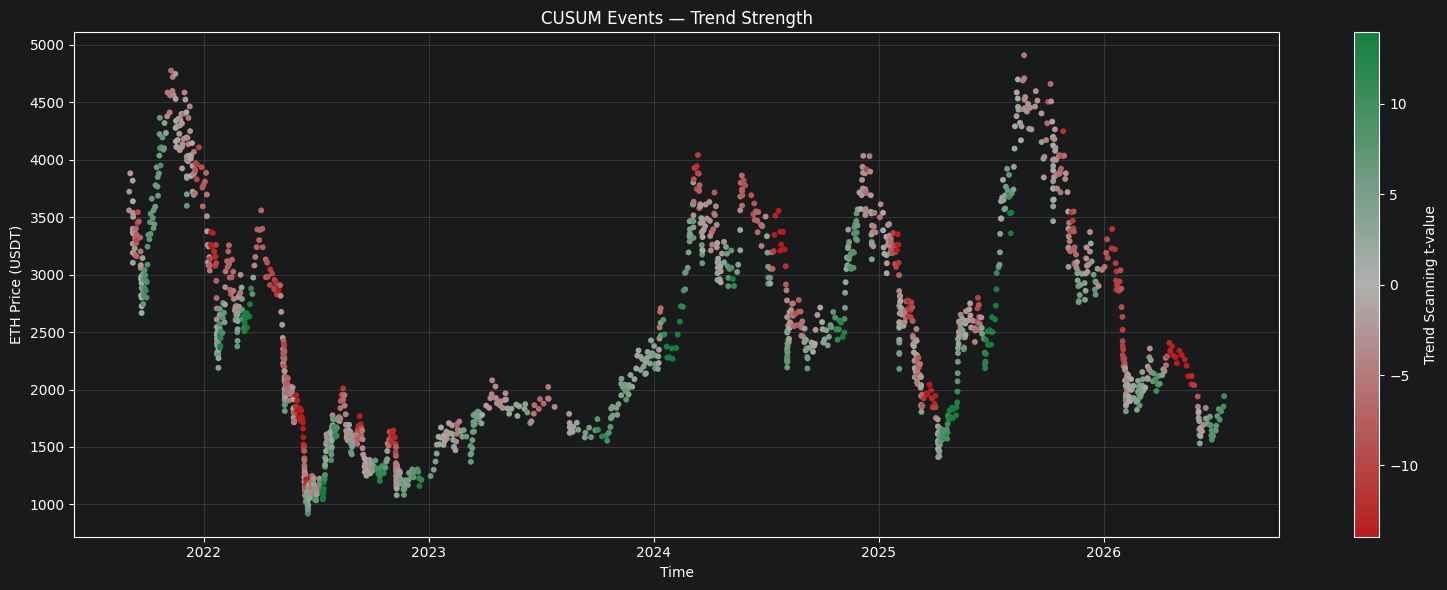

count    1642.000000
mean       -0.131195
std         7.247257
min       -31.736160
5%        -11.349556
25%        -4.935947
50%        -1.190976
75%         4.877068
95%        11.108861
max        23.746735
Name: t_value, dtype: float64


In [433]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

labels = tr_scan_labels.dropna(subset=["t_value"])
prices = df.loc[labels.index, "close"]

t_values = labels["t_value"]

# Limităm doar scala culorilor la percentila 95
limit = np.percentile(np.abs(t_values), 95)

cmap = LinearSegmentedColormap.from_list(
    "trend", ["#b91c1c", "#b0b0b0", "#15803d"]
)

norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

plt.figure(figsize=(16, 6))

scatter = plt.scatter(
    prices.index,
    prices,
    c=t_values,
    cmap=cmap,
    norm=norm,
    s=18,
    alpha=1,
    edgecolors="none"
)

plt.colorbar(scatter, label="Trend Scanning t-value")
plt.title("CUSUM Events — Trend Strength")
plt.xlabel("Time")
plt.ylabel("ETH Price (USDT)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(t_values.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

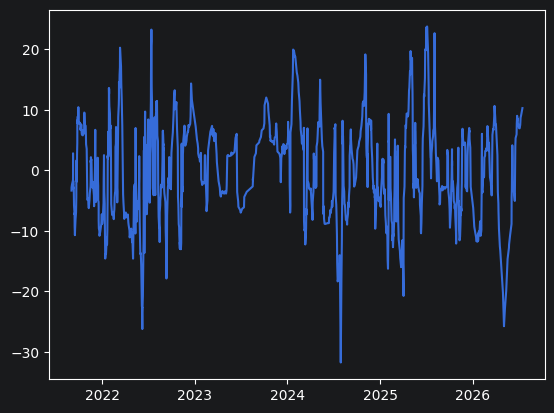

In [434]:
plt.plot(tr_scan_labels["t_value"])
plt.show()

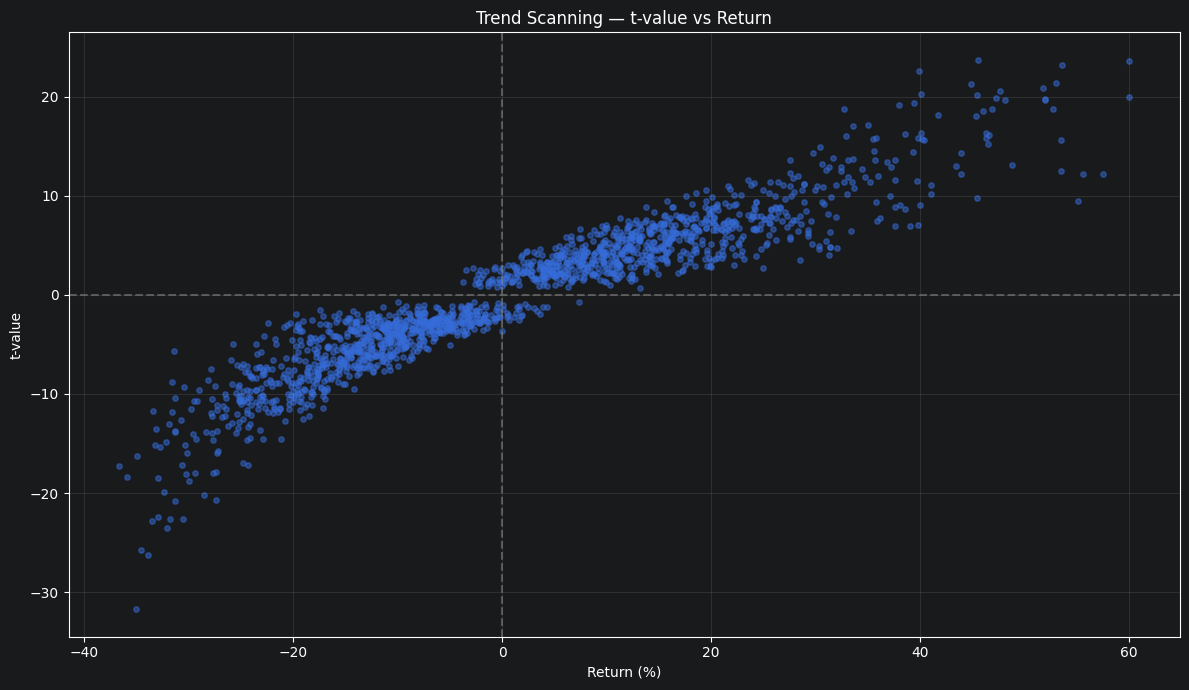

Pearson correlation: 0.9439
Spearman correlation: 0.9552
|t| vs |Return| correlation: 0.8190


In [435]:
import matplotlib.pyplot as plt
import numpy as np

labels = tr_scan_labels.dropna(subset=["t_value", "ret"])

x = labels["ret"] * 100
y = labels["t_value"]

plt.figure(figsize=(12, 7))

plt.scatter(x, y, alpha=0.5, s=15)

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.axvline(0, color="gray", linestyle="--", alpha=0.6)

plt.xlabel("Return (%)")
plt.ylabel("t-value")
plt.title("Trend Scanning — t-value vs Return")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Corelații
print(f"Pearson correlation: {x.corr(y):.4f}")
print(f"Spearman correlation: {x.corr(y, method='spearman'):.4f}")

# Relația dintre intensitatea trendului și amplitudinea randamentului
print(f"|t| vs |Return| correlation: {x.abs().corr(y.abs()):.4f}")

In [436]:
tr_scan_labels

,t1,t_value,ret,bin
2021-09-01 14:31:21.082000+00:00,2021-09-07 15:17:57.227000+00:00,-3.353013,-0.053646,-1.0
2021-09-01 16:46:13.443000+00:00,2021-09-11 10:24:55.369000+00:00,-2.860464,-0.109393,-1.0
2021-09-03 08:50:28.625000+00:00,2021-09-11 10:24:55.369000+00:00,-2.365062,-0.145972,-1.0
2021-09-07 08:27:37.376000+00:00,2021-09-13 02:31:17.144000+00:00,-1.631185,-0.142295,-1.0
2021-09-07 14:43:58.672000+00:00,2021-09-13 02:31:17.144000+00:00,-0.724518,-0.099910,-1.0
...,...,...,...,...
2026-08-22 05:10:54.257726+00:00,NaT,NaN,NaN,NaN
2026-08-24 11:40:42.841162+00:00,NaT,NaN,NaN,NaN
2026-08-27 08:30:11.894346+00:00,NaT,NaN,NaN,NaN
2026-08-28 16:23:53.703751+00:00,NaT,NaN,NaN,NaN


In [437]:
df_labeled = df.join(tr_scan_labels, how="inner", rsuffix="_trend")

df_labeled.head()

,bar_id,series_id,bar_type,bar_seq,segment_id,bar_start_us,bar_end_us,first_trade_ts_us,last_trade_ts_us,first_trade_id,...,impact_per_sell_pressure_50bps,quote_spread,quote_spread_bps,quote_age_s,quote_twa_spread_bps,quote_valid_time_frac,t1,t_value,ret,bin
2021-09-01 14:31:21.082000+00:00,binance_spot_ETHUSDT_volume_959ebe91615f:89,binance_spot_ETHUSDT_volume_959ebe91615f,volume,89,0,1630506249919000,1630506681082000,1630506249919000,1630506681082000,583228025,...,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-07 15:17:57.227000+00:00,-3.353013,-0.053646,-1.0
2021-09-01 16:46:13.443000+00:00,binance_spot_ETHUSDT_volume_959ebe91615f:116,binance_spot_ETHUSDT_volume_959ebe91615f,volume,116,0,1630514704289000,1630514773443000,1630514704289000,1630514773443000,583528493,...,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-11 10:24:55.369000+00:00,-2.860464,-0.109393,-1.0
2021-09-03 08:50:28.625000+00:00,binance_spot_ETHUSDT_volume_959ebe91615f:319,binance_spot_ETHUSDT_volume_959ebe91615f,volume,319,0,1630658978345000,1630659028625000,1630658978345000,1630659028625000,586170196,...,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-11 10:24:55.369000+00:00,-2.365062,-0.145972,-1.0
2021-09-07 08:27:37.376000+00:00,binance_spot_ETHUSDT_volume_959ebe91615f:676,binance_spot_ETHUSDT_volume_959ebe91615f,volume,676,0,1631003049883000,1631003257376000,1631003049901000,1631003257376000,590649760,...,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-13 02:31:17.144000+00:00,-1.631185,-0.142295,-1.0
2021-09-07 14:43:58.672000+00:00,binance_spot_ETHUSDT_volume_959ebe91615f:740,binance_spot_ETHUSDT_volume_959ebe91615f,volume,740,0,1631025690560000,1631025838672000,1631025690560000,1631025838672000,591225182,...,NaN,NaN,NaN,NaN,NaN,NaN,2021-09-13 02:31:17.144000+00:00,-0.724518,-0.099910,-1.0


In [438]:
df_labeled = df_labeled.loc[:, df_labeled.isna().mean() <= 0.10]

In [439]:
df_labeled.dropna(inplace=True)

In [440]:
df_labeled.shape

(1573, 132)

In [441]:
list(df_labeled)

['bar_id',
 'series_id',
 'bar_type',
 'bar_seq',
 'segment_id',
 'bar_start_us',
 'bar_end_us',
 'first_trade_ts_us',
 'last_trade_ts_us',
 'first_trade_id',
 'last_trade_id',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'notional_usdt',
 'n_trades',
 'n_messages',
 'threshold_frozen',
 'complete',
 'bar_status',
 'bar_available_us',
 'decision_time_us',
 'bar_provenance',
 'bar_start',
 'bar_end',
 'bar_available',
 'decision_time',
 'ret_bars_1',
 'ret_bars_5',
 'ret_bars_20',
 'ret_5min',
 'ret_5min_ref_age_s',
 'ret_1h',
 'ret_1h_ref_age_s',
 'ret_4h',
 'ret_4h_ref_age_s',
 'ret_1d',
 'ret_1d_ref_age_s',
 'ret_7d',
 'ret_7d_ref_age_s',
 'ret_30d',
 'ret_30d_ref_age_s',
 'rv_1h',
 'rvol_1h',
 'rvol_ann_1h',
 'rv_1d',
 'rvol_1d',
 'rvol_ann_1d',
 'rv_7d',
 'rvol_7d',
 'rvol_ann_7d',
 'rv_30d',
 'rvol_30d',
 'rvol_ann_30d',
 'rv_bars_20',
 'rv_bars_100',
 'bar_duration_s',
 'trade_span_s',
 'avg_trade_size',
 'trade_intensity_per_s',
 'volume_per_s',
 'notional_per_s',
 'aggr_buy_

In [442]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score
)

# 1. Select features
features = [

 'volume',
'ret_bars_1',
 'ret_bars_5',
 'ret_bars_20',
    'ret_5min',

     'premium_fx_coinbase_eth_1m',
'premium_raw_coinbase_btc_1m',
     'premium_raw_coinbase_btc_1d',
    'premium_raw_coinbase_eth_1d',

]
# 2. Prepare dataset
data = df_labeled.sort_index().copy()

# Binary classification: -1 = Downtrend, +1 = Uptrend
data = data[data["bin"].isin([-1, 1])]

# 3. Chronological train/test split (80/20)
split_idx = int(len(data) * 0.8)

train = data.iloc[:split_idx].copy()
test = data.iloc[split_idx:].copy()

# 4. Purging: remove training labels overlapping test period
test_start = pd.to_datetime(test.index[0], utc=True)
train_t1 = pd.to_datetime(train["t1"], utc=True)

train = train.loc[train_t1 < test_start]

# 5. Features and target
X_train = train[features]
y_train = train["bin"].astype(int)

X_test = test[features]
y_test = test["bin"].astype(int)

print(f"Train samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Features: {len(features)}")

# 6. Random Forest
model = RandomForestClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=8,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 7. Predictions
y_pred = model.predict(X_test)

positive_idx = list(model.classes_).index(1)
y_proba = model.predict_proba(X_test)[:, positive_idx]

# 8. Evaluation
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred,
    labels=[-1, 1],
    target_names=["Downtrend", "Uptrend"],
    zero_division=0
))

print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")

if y_test.nunique() == 2:
    print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
else:
    print("ROC-AUC unavailable: test set contains one class.")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[-1, 1]))

Train samples: 1247
Test samples: 315
Features: 9

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   Downtrend       0.58      0.79      0.67       167
     Uptrend       0.61      0.36      0.46       148

    accuracy                           0.59       315
   macro avg       0.60      0.58      0.56       315
weighted avg       0.59      0.59      0.57       315

Balanced Accuracy: 0.5776
ROC-AUC: 0.5910

Confusion Matrix:
[[132  35]
 [ 94  54]]


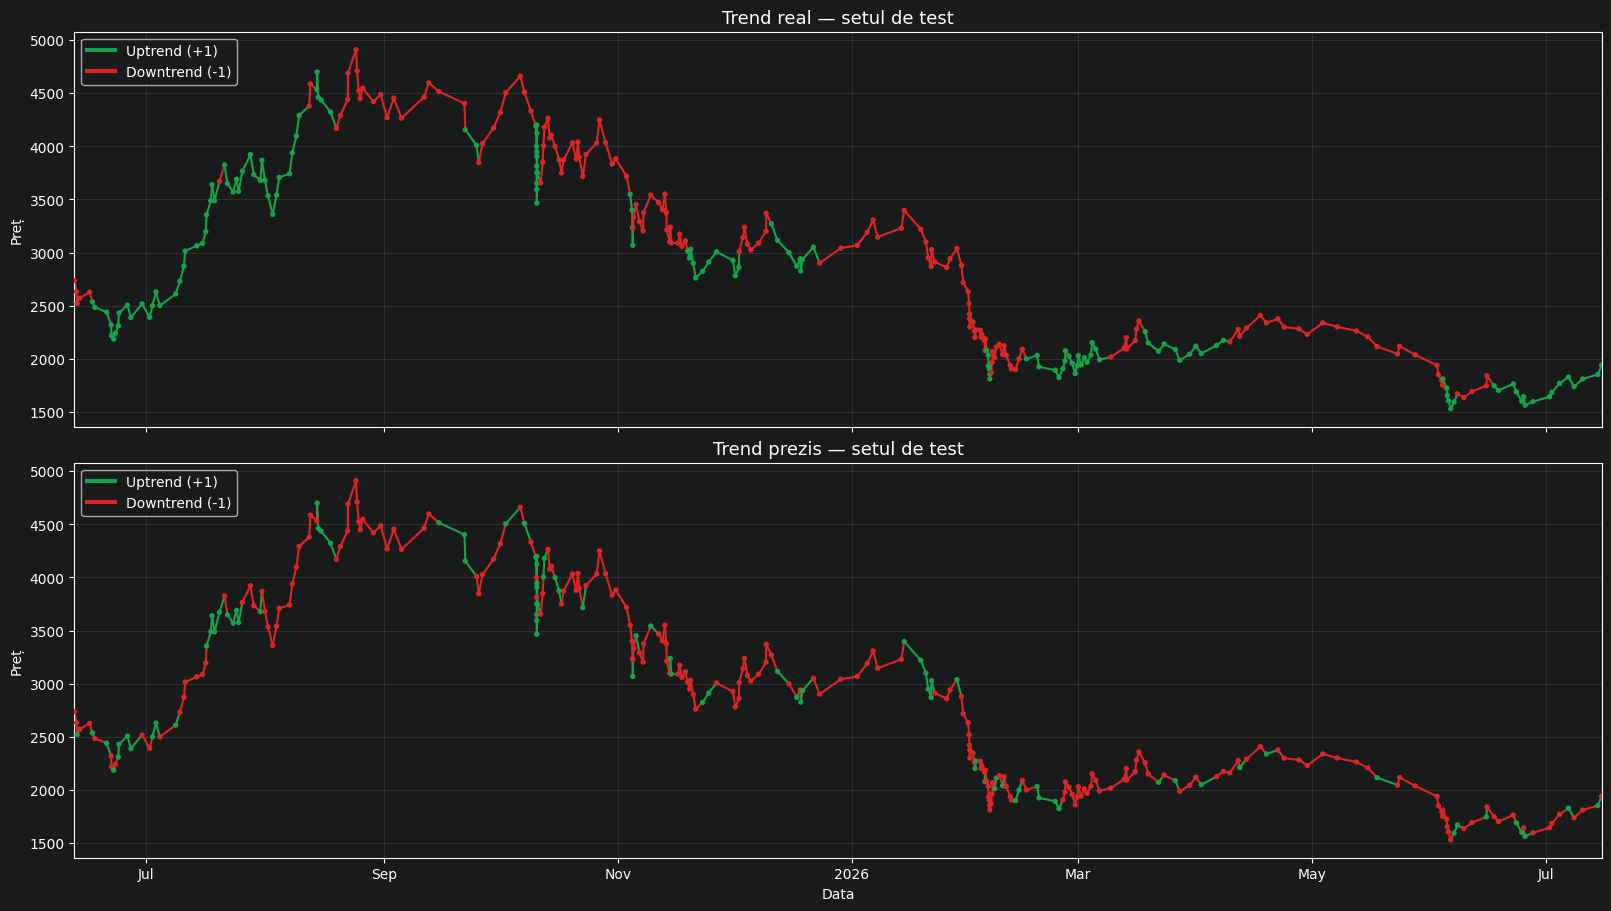

In [443]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# 1. Prețurile și etichetele, în aceeași ordine ca predicțiile
test_prices = (
    test["close"]
    if "close" in test.columns
    else df["close"].reindex(test.index)
)

prices = pd.to_numeric(test_prices, errors="coerce").to_numpy()
actual = test["bin"].astype(int).to_numpy()
predicted = np.asarray(y_pred).reshape(-1)

if not (len(prices) == len(actual) == len(predicted)):
    raise ValueError("Prețurile, etichetele și predicțiile nu sunt aliniate.")

if len(prices) < 2 or not np.isfinite(prices).all():
    raise ValueError("Sunt necesare cel puțin două prețuri valide.")

if not np.isin(predicted, [-1, 1]).all():
    raise ValueError("Predicțiile trebuie să fie -1 sau +1.")

dates = mdates.date2num(pd.DatetimeIndex(test.index).to_pydatetime())

UP_COLOR = "#16a34a"
DOWN_COLOR = "#dc2626"

# 2. Funcție pentru desenarea prețului colorat
def plot_trends(ax, labels, title):
    colors = np.where(labels == 1, UP_COLOR, DOWN_COLOR)

    points = np.column_stack([dates, prices])
    segments = np.stack([points[:-1], points[1:]], axis=1)

    # Segmentul primește culoarea etichetei barei de la început.
    collection = LineCollection(
        segments,
        colors=colors[:-1],
        linewidths=1.5,
    )
    ax.add_collection(collection)

    # Fiecare punct are culoarea propriei etichete.
    ax.scatter(dates, prices, c=colors, s=8, zorder=3)

    ax.set_xlim(dates[0], dates[-1])
    ax.autoscale_view(scalex=False, scaley=True)
    ax.xaxis_date()
    ax.set_title(title, fontsize=13)
    ax.set_ylabel("Preț")
    ax.grid(alpha=0.2)

# 3. Aceleași axe pentru comparație
fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

plot_trends(axes[0], actual, "Trend real — setul de test")
plot_trends(axes[1], predicted, "Trend prezis — setul de test")

legend = [
    Line2D([0], [0], color=UP_COLOR, lw=3, label="Uptrend (+1)"),
    Line2D([0], [0], color=DOWN_COLOR, lw=3, label="Downtrend (-1)"),
]

for ax in axes:
    ax.legend(handles=legend, loc="upper left")

locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[1].set_xlabel("Data")

plt.show()